# Aula 24 - Notebook: Árvore de Atingibilidade e Árvore de Cobertura em Redes de Petri na Fábrica de Paçoca

**Disciplina:** ECAA08 — Automática (2026.2) — UNIFEI
**Projeto:** SCADA-Core Automática / Linha de Produção de Paçoca — **Equipe:** Grupo 7

Este notebook implementa do zero a **Árvore de Atingibilidade** e a **Árvore de Cobertura (Karp-Miller)** e as aplica a dois subsistemas da fábrica de paçoca com naturezas diferentes:

| Parte | Subsistema | CLP | O que a árvore prova |
| :---: | :--- | :---: | :--- |
| **A** | Gerenciamento do queimador do **forno de torra** (purga → ignição → torra → *trip*) | CLP 02 | Propriedades de **segurança**: gás nunca aberto sem exaustão e sem chama; purga obrigatória após *trip* |
| **B** | **Linha de massa**: dosagem paralela (amendoim/açúcar/sal) → moinhos redundantes → homogeneizador `HOM-301` → moega pulmão `MOE-302` → prensa `PRN-401` | CLP 03 / CLP 04 | **Limitação**: o símbolo $\omega$ denuncia acúmulo ilimitado de massa |
| **C** | Linha de massa corrigida com **lugares complementares** de capacidade | CLP 03 / CLP 04 | Rede limitada, viva, reversível e que permite acionar o moinho reserva `MOI-301B` em paralelo |

Ferramentas adicionais: cálculo de **invariantes de lugar** ($y^T C = 0$) por eliminação de Gauss com frações exatas e verificação de uma **propriedade de caminho** (purga obrigatória) sobre o grafo de atingibilidade.

### 1. Estrutura de Dados da Rede de Petri

$N = (P, T, Pre, Post, M_0)$, com $C = Post - Pre$. Uma transição $t_j$ está habilitada em $M$ se $M \ge Pre(\cdot, t_j)$; ao disparar, $M' = M + C\,\vec{e}_j$.

Para ficar legível, cada transição é declarada como um par de dicionários `{lugar: peso}` (entradas e saídas), e a classe monta as matrizes $Pre$, $Post$ e $C$.

In [1]:
from collections import deque
from fractions import Fraction
from math import gcd
from functools import reduce
import pandas as pd
import matplotlib.pyplot as plt

OMEGA = float("inf")


class RedeDePetri:
    def __init__(self, nome, lugares, transicoes, m0):
        # lugares: lista de nomes; transicoes: {nome: (entradas, saidas)}; m0: {lugar: fichas}
        self.nome = nome
        self.P = list(lugares)
        self.T = list(transicoes)
        idx = {p: i for i, p in enumerate(self.P)}
        self.Pre = [[0] * len(self.T) for _ in self.P]
        self.Post = [[0] * len(self.T) for _ in self.P]
        for j, t in enumerate(self.T):
            entradas, saidas = transicoes[t]
            for p, w in entradas.items():
                self.Pre[idx[p]][j] = w
            for p, w in saidas.items():
                self.Post[idx[p]][j] = w
        self.C = [[self.Post[i][j] - self.Pre[i][j] for j in range(len(self.T))] for i in range(len(self.P))]
        self.M0 = tuple(m0.get(p, 0) for p in self.P)

    def habilitada(self, M, j):
        return all(M[i] >= self.Pre[i][j] for i in range(len(self.P)))

    def disparar(self, M, j):
        return tuple(OMEGA if M[i] == OMEGA else M[i] + self.C[i][j] for i in range(len(self.P)))

    def matriz(self, qual="C"):
        dados = {"Pre": self.Pre, "Post": self.Post, "C": self.C}[qual]
        return pd.DataFrame(dados, index=self.P, columns=[t.split("_")[0] for t in self.T])


def fmt(M):
    return "(" + ",".join("ω" if x == OMEGA else str(int(x)) for x in M) + ")"

def marcados(rdp, M):
    # Lista legível dos lugares com fichas.
    return ", ".join((p if M[i] == 1 else f"{p}={'ω' if M[i] == OMEGA else int(M[i])}")
                     for i, p in enumerate(rdp.P) if M[i] != 0)

### 2. Algoritmo da Árvore de Cobertura (Karp-Miller)

Uma única função serve aos dois casos: se a rede for limitada, nenhum $\omega$ aparece e a árvore obtida **é** a árvore de atingibilidade.

1. A raiz é $M_0$. Cada nó guarda o caminho de ancestrais até a raiz.
2. Um nó cuja marcação já apareceu antes na árvore é **duplicado** (folha, não é expandido).
3. Um nó sem transições habilitadas é **terminal (deadlock)**.
4. **Aceleração $\omega$:** se a nova marcação $M'$ cobre estritamente um ancestral $M$ do mesmo ramo ($M' \ge M$ e $M' \ne M$), as coordenadas em que $M'(p) > M(p)$ viram $\omega$ — o ciclo que levou de $M$ a $M'$ pode ser repetido indefinidamente.

A função também devolve o **grafo de cobertura** (marcações distintas e arcos rotulados), usado nas auditorias.

In [2]:
def acelerar_omega(M_novo, ancestrais):
    M = list(M_novo)
    mudou = True
    while mudou:  # repete porque um ω novo pode permitir cobrir outro ancestral
        mudou = False
        for A in ancestrais:
            if all(m >= a for m, a in zip(M, A)) and tuple(M) != tuple(A):
                for i in range(len(M)):
                    if M[i] > A[i] and M[i] != OMEGA:
                        M[i] = OMEGA
                        mudou = True
    return tuple(M)


def arvore_de_cobertura(rdp, max_nos=5000):
    nos = [{"id": 0, "M": rdp.M0, "pai": None, "via": None, "tipo": "raiz"}]
    grafo = {rdp.M0: []}            # marcação -> [(transição, marcação destino)]
    ja_vistas = {rdp.M0}
    fila = deque([(0, [rdp.M0])])
    while fila:
        nid, ancestrais = fila.popleft()
        M = nos[nid]["M"]
        habilitadas = [j for j in range(len(rdp.T)) if rdp.habilitada(M, j)]
        if not habilitadas:
            nos[nid]["tipo"] = "DEADLOCK"
            continue
        for j in habilitadas:
            M2 = acelerar_omega(rdp.disparar(M, j), ancestrais)
            grafo.setdefault(M, []).append((rdp.T[j], M2))
            grafo.setdefault(M2, [])
            novo = {"id": len(nos), "M": M2, "pai": nid, "via": rdp.T[j],
                    "tipo": "duplicado" if M2 in ja_vistas else "novo"}
            nos.append(novo)
            if M2 not in ja_vistas:
                ja_vistas.add(M2)
                fila.append((novo["id"], ancestrais + [M2]))
            if len(nos) >= max_nos:
                raise RuntimeError("Árvore excedeu o limite de nós")
    return nos, grafo


def tabela_arvore(rdp, nos):
    return pd.DataFrame([{"Nó": f"N{n['id']}", "Pai": "—" if n["pai"] is None else f"N{n['pai']}",
                          "Via": n["via"] or "—", "Marcação": fmt(n["M"]), "Lugares marcados": marcados(rdp, n["M"]),
                          "Tipo": n["tipo"]} for n in nos])

### 3. Ferramentas de Auditoria

* **Limitação / segurança (1-limitada)**: máximo de fichas por lugar no grafo de cobertura.
* **Deadlock**: marcações sem sucessores.
* **Reversibilidade**: toda marcação alcançável consegue voltar a $M_0$ (busca no grafo reverso).
* **Vivacidade L4** (para redes limitadas e reversíveis): toda transição aparece em algum arco do grafo.
* **Invariantes de lugar**: base inteira do núcleo à esquerda de $C$ ($y^T C = 0$). Se $y^T C = 0$, então $y^T M = y^T M_0$ para toda marcação alcançável — uma lei de conservação provada **sem enumerar estados**.

In [3]:
def auditar(rdp, grafo, titulo):
    estados = list(grafo)
    maximos = [max(M[i] for M in estados) for i in range(len(rdp.P))]
    limitada = all(v != OMEGA for v in maximos)
    deadlocks = [M for M in estados if not grafo[M]]
    reverso = {M: set() for M in estados}
    for M, arcos in grafo.items():
        for _, M2 in arcos:
            reverso[M2].add(M)
    alcanca_m0, pilha = {rdp.M0}, [rdp.M0]
    while pilha:
        x = pilha.pop()
        for y in reverso[x]:
            if y not in alcanca_m0:
                alcanca_m0.add(y); pilha.append(y)
    reversivel = limitada and len(alcanca_m0) == len(estados)
    disparadas = {t for arcos in grafo.values() for t, _ in arcos}
    viva = reversivel and disparadas == set(rdp.T)

    print("=" * 70)
    print(f"AUDITORIA — {titulo}")
    print("=" * 70)
    print(f"Marcações distintas no grafo:   {len(estados)}")
    print(f"Limitada (sem ω):               {'SIM' if limitada else 'NÃO — risco de acúmulo/transbordo'}")
    print(f"Segura (1-limitada):            {'SIM' if all(v <= 1 for v in maximos) else 'NÃO'}")
    print(f"Deadlocks:                      {len(deadlocks)}")
    print(f"Reversível (volta a M0):        {'SIM' if reversivel else 'NÃO / indecidível com ω'}")
    print(f"Viva (L4):                      {'SIM' if viva else 'NÃO / indecidível com ω'}")
    print(f"Transições nunca disparadas:    {sorted(set(rdp.T) - disparadas) or 'nenhuma'}")
    return pd.DataFrame({"Lugar": rdp.P, "Máx. de fichas": ["ω" if v == OMEGA else int(v) for v in maximos]})


def invariantes_de_lugar(rdp):
    # Base do núcleo de C^T (y^T C = 0) por eliminação de Gauss-Jordan com frações exatas.
    n_p, n_t = len(rdp.P), len(rdp.T)
    A = [[Fraction(rdp.C[i][j]) for i in range(n_p)] for j in range(n_t)]   # A = C^T  (|T| x |P|)
    pivos, linha = [], 0
    for col in range(n_p):
        piv = next((r for r in range(linha, n_t) if A[r][col] != 0), None)
        if piv is None:
            continue
        A[linha], A[piv] = A[piv], A[linha]
        A[linha] = [x / A[linha][col] for x in A[linha]]
        for r in range(n_t):
            if r != linha and A[r][col] != 0:
                f = A[r][col]
                A[r] = [a - f * b for a, b in zip(A[r], A[linha])]
        pivos.append(col); linha += 1
    livres = [c for c in range(n_p) if c not in pivos]
    base = []
    for lv in livres:
        y = [Fraction(0)] * n_p
        y[lv] = Fraction(1)
        for r, pc in enumerate(pivos):
            y[pc] = -A[r][lv]
        mmc = reduce(lambda a, b: a * b // gcd(a, b), [x.denominator for x in y])
        y = [int(x * mmc) for x in y]
        g = reduce(gcd, [abs(x) for x in y if x])
        base.append([x // g for x in y])
    return base


def mostrar_invariante(rdp, y):
    termos = []
    for coef, p in zip(y, rdp.P):
        if coef:
            termos.append(("+ " if coef > 0 else "- ") + (f"{abs(coef)}·" if abs(coef) != 1 else "") + f"M({p})")
    lhs = " ".join(termos).lstrip("+ ")
    return f"{lhs} = {sum(c * m for c, m in zip(y, rdp.M0))}"


def verificar_invariante(rdp, y):
    return all(sum(y[i] * rdp.C[i][j] for i in range(len(rdp.P))) == 0 for j in range(len(rdp.T)))

---
## Parte A — Forno de Torra: Gerenciamento do Queimador (CLP 02)

O forno de torra é o equipamento de maior risco da planta (gás natural/GLP, operação entre 160 °C e 180 °C, poeira e óleo de amendoim). A sequência segue a lógica clássica de gerenciamento de queimadores: **antes de qualquer ignição, a câmara precisa ser purgada com ar** para remover gás residual; após um *trip*, a purga deve ser refeita.

| Lugar | Significado físico | Instrumentos | $M_0$ |
| :--- | :--- | :--- | :---: |
| `P1_DESLIGADO` | Forno parado, gás fechado | — | 1 |
| `P2_PURGA` | Purga com ar em andamento | exaustor, `FS-201` | 0 |
| `P3_PRONTO_IGNICAO` | Purga concluída, aguardando ignição | — | 0 |
| `P4_TORRANDO` | Chama estável, esteira do forno ligada | `TS-201`, `TT-201`, `M-201` | 0 |
| `P5_LOCKOUT` | Bloqueio por segurança, alarme ativo | `ALM-201` | 0 |
| `P6_EXAUSTOR_ON` | Exaustão de gases com fluxo OK | `FS-201` | 0 |
| `P7_GAS_ABERTO` | Válvula de corte rápido de gás aberta | `XV-201` | 0 |

| Transição | Evento / ação de controle |
| :--- | :--- |
| `T1_INICIAR_PURGA` | Liga o exaustor e inicia a temporização de purga |
| `T2_FIM_PURGA` | Tempo de purga cumprido com `FS-201` OK |
| `T3_IGNICAO_OK` | Abre `XV-201` e `TS-201` confirma chama dentro do tempo de segurança |
| `T4_FALHA_IGNICAO` | Chama não confirmada → bloqueio |
| `T5_TRIP` | Qualquer trip da BDT da Aula 21: `ESD-100`, sobretemperatura `TT-201`, perda de exaustão `FS-201`, perda de chama `TS-201` ou esteira `M-201` parada → fecha `XV-201` |
| `T6_DESLIGAR` | Parada normal: fecha gás e desliga o exaustor |
| `T7_RESET` | Reset manual após inspeção; exaustor desliga e o forno volta a `P1_DESLIGADO` |

In [4]:
lugares_A = ["P1_DESLIGADO", "P2_PURGA", "P3_PRONTO_IGNICAO", "P4_TORRANDO",
             "P5_LOCKOUT", "P6_EXAUSTOR_ON", "P7_GAS_ABERTO"]
transicoes_A = {
    "T1_INICIAR_PURGA": ({"P1_DESLIGADO": 1}, {"P2_PURGA": 1, "P6_EXAUSTOR_ON": 1}),
    "T2_FIM_PURGA":     ({"P2_PURGA": 1}, {"P3_PRONTO_IGNICAO": 1}),
    "T3_IGNICAO_OK":    ({"P3_PRONTO_IGNICAO": 1}, {"P4_TORRANDO": 1, "P7_GAS_ABERTO": 1}),
    "T4_FALHA_IGNICAO": ({"P3_PRONTO_IGNICAO": 1}, {"P5_LOCKOUT": 1}),
    "T5_TRIP":          ({"P4_TORRANDO": 1, "P7_GAS_ABERTO": 1}, {"P5_LOCKOUT": 1}),
    "T6_DESLIGAR":      ({"P4_TORRANDO": 1, "P7_GAS_ABERTO": 1, "P6_EXAUSTOR_ON": 1}, {"P1_DESLIGADO": 1}),
    "T7_RESET":         ({"P5_LOCKOUT": 1, "P6_EXAUSTOR_ON": 1}, {"P1_DESLIGADO": 1}),
}
forno = RedeDePetri("Forno de torra (BMS)", lugares_A, transicoes_A, {"P1_DESLIGADO": 1})
print("Matriz de incidência C = Post - Pre:")
display(forno.matriz("C"))

Matriz de incidência C = Post - Pre:


,T1,T2,T3,T4,T5,T6,T7
P1_DESLIGADO,-1,0,0,0,0,1,1
P2_PURGA,1,-1,0,0,0,0,0
P3_PRONTO_IGNICAO,0,1,-1,-1,0,0,0
P4_TORRANDO,0,0,1,0,-1,-1,0
P5_LOCKOUT,0,0,0,1,1,0,-1
P6_EXAUSTOR_ON,1,0,0,0,0,-1,-1
P7_GAS_ABERTO,0,0,1,0,-1,-1,0


In [5]:
nos_A, grafo_A = arvore_de_cobertura(forno)
display(tabela_arvore(forno, nos_A))

,Nó,Pai,Via,Marcação,Lugares marcados,Tipo
0,N0,—,—,"(1,0,0,0,0,0,0)",P1_DESLIGADO,raiz
1,N1,N0,T1_INICIAR_PURGA,"(0,1,0,0,0,1,0)","P2_PURGA, P6_EXAUSTOR_ON",novo
2,N2,N1,T2_FIM_PURGA,"(0,0,1,0,0,1,0)","P3_PRONTO_IGNICAO, P6_EXAUSTOR_ON",novo
3,N3,N2,T3_IGNICAO_OK,"(0,0,0,1,0,1,1)","P4_TORRANDO, P6_EXAUSTOR_ON, P7_GAS_ABERTO",novo
4,N4,N2,T4_FALHA_IGNICAO,"(0,0,0,0,1,1,0)","P5_LOCKOUT, P6_EXAUSTOR_ON",novo
5,N5,N3,T5_TRIP,"(0,0,0,0,1,1,0)","P5_LOCKOUT, P6_EXAUSTOR_ON",duplicado
6,N6,N3,T6_DESLIGAR,"(1,0,0,0,0,0,0)",P1_DESLIGADO,duplicado
7,N7,N4,T7_RESET,"(1,0,0,0,0,0,0)",P1_DESLIGADO,duplicado


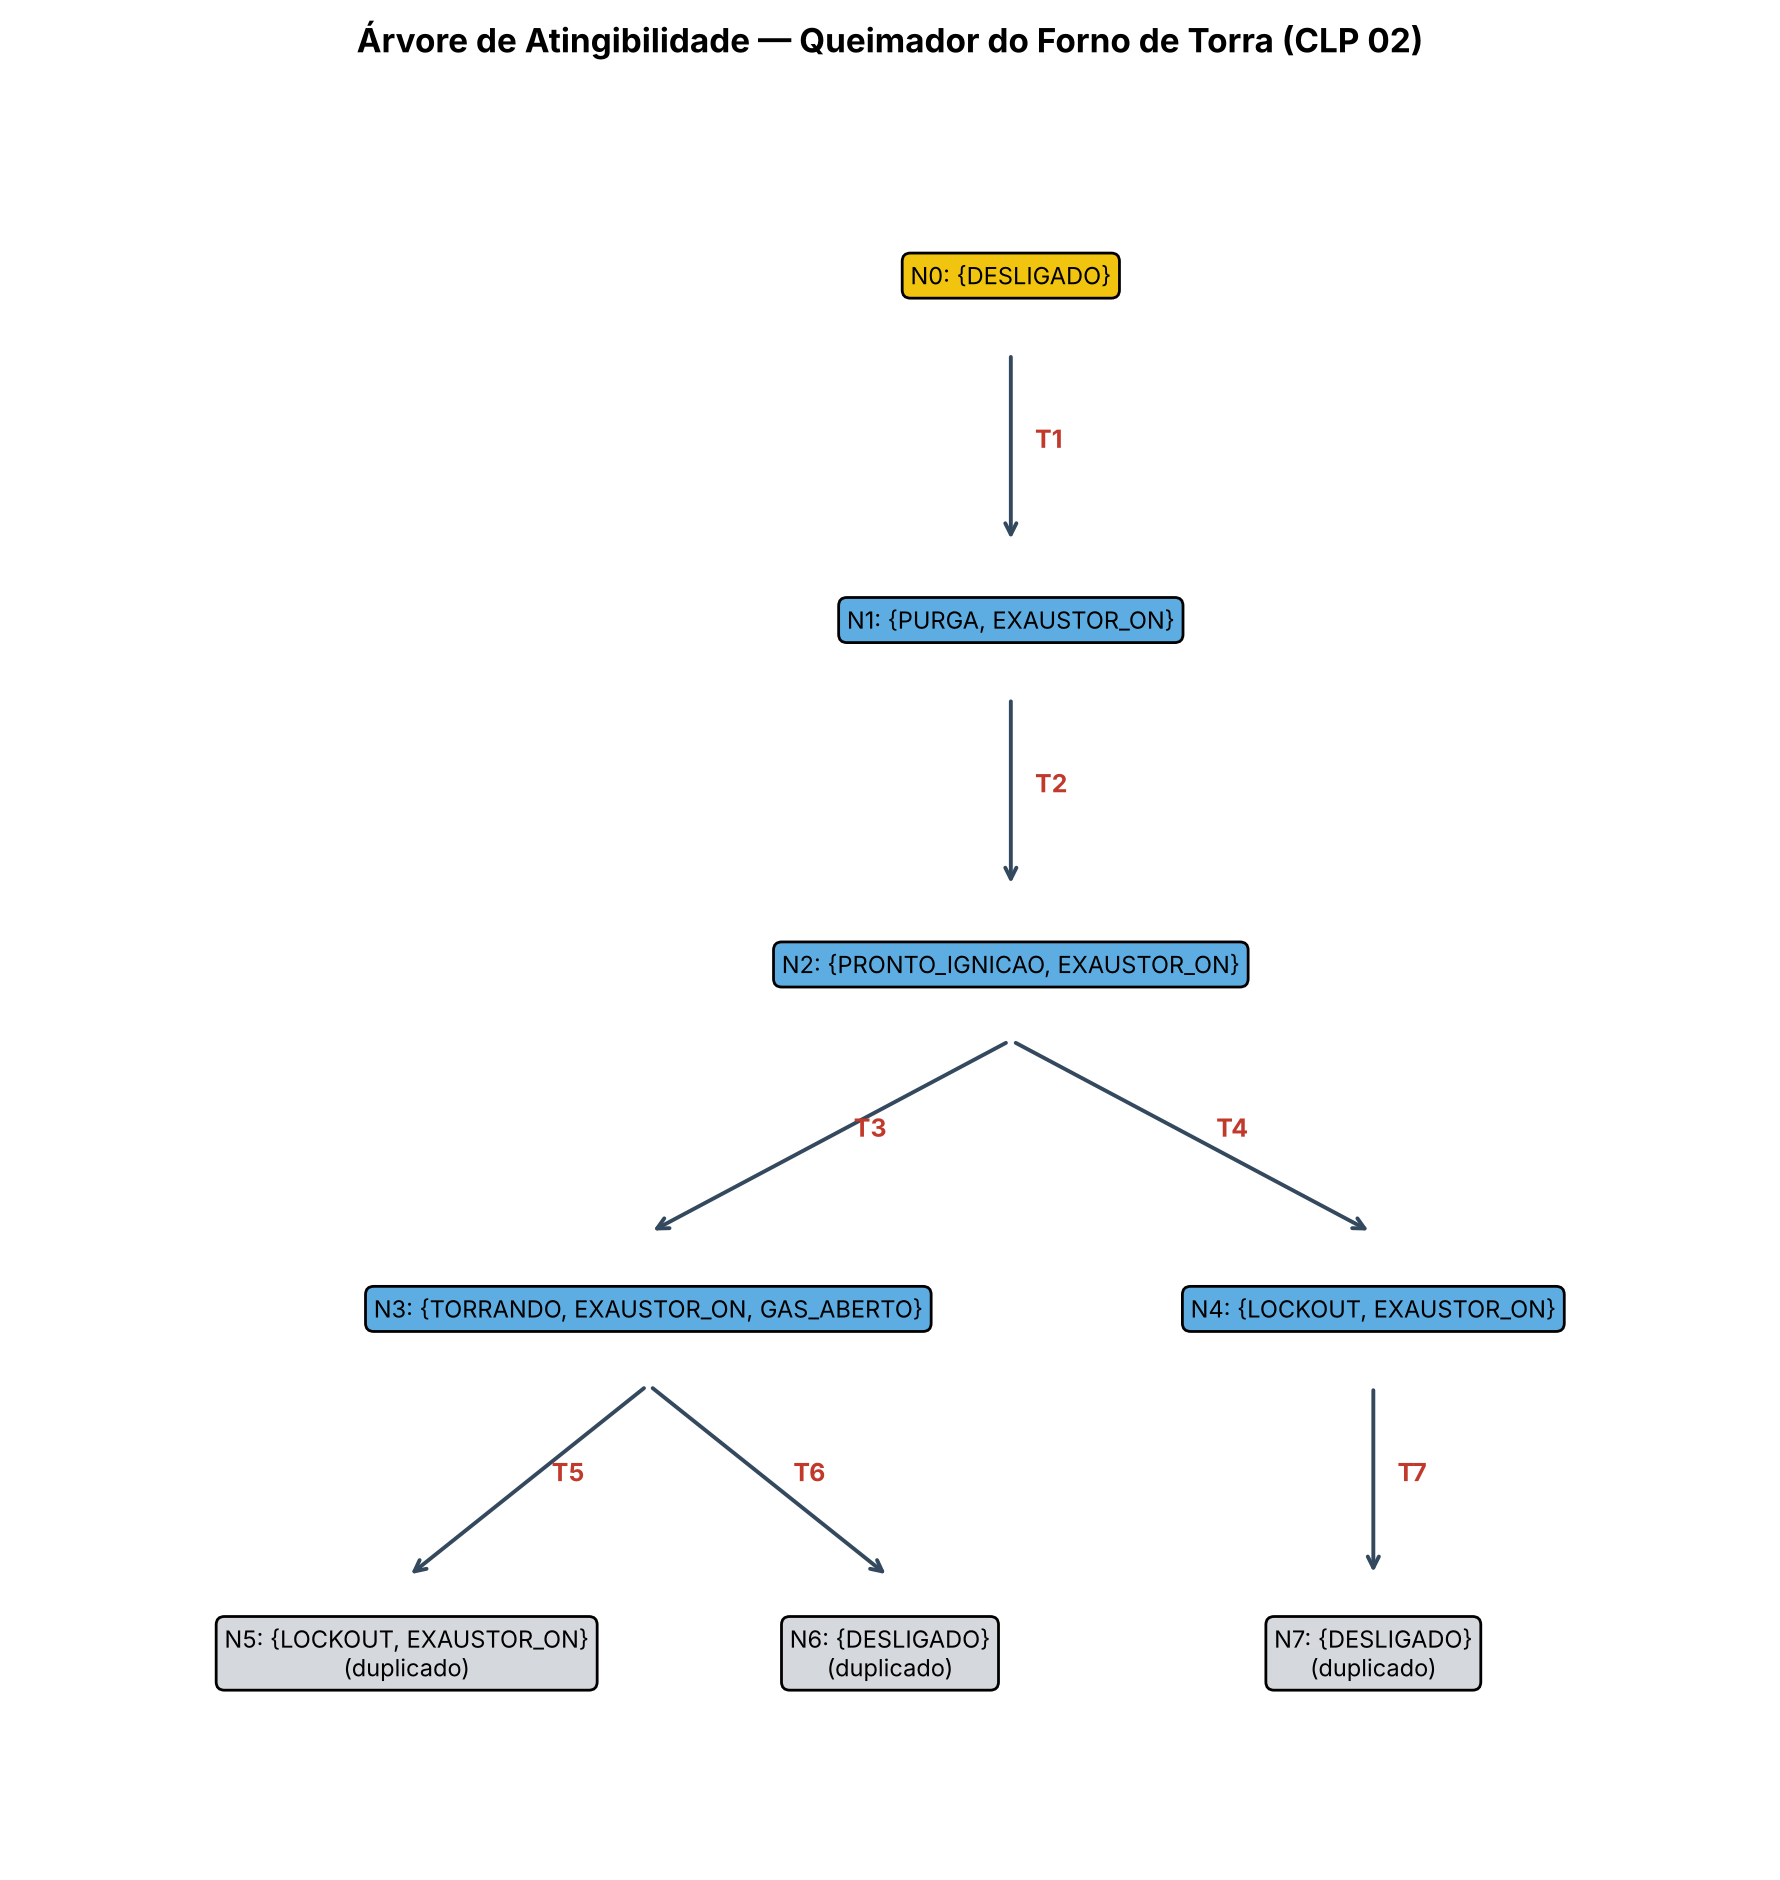

In [6]:
def desenhar_arvore(rdp, nos, titulo, abreviar=None):
    filhos = {n["id"]: [] for n in nos}
    for n in nos:
        if n["pai"] is not None:
            filhos[n["pai"]].append(n["id"])
    pos, prox_x = {}, [0]
    def layout(nid, prof):
        if not filhos[nid]:
            pos[nid] = (prox_x[0], -prof); prox_x[0] += 1
        else:
            for f in filhos[nid]:
                layout(f, prof + 1)
            xs = [pos[f][0] for f in filhos[nid]]
            pos[nid] = (sum(xs) / len(xs), -prof)
    layout(0, 0)
    cores = {"raiz": "#F1C40F", "novo": "#5DADE2", "duplicado": "#D5D8DC", "DEADLOCK": "#E74C3C"}
    fig, ax = plt.subplots(figsize=(max(9, 2.3 * prox_x[0]), 1.9 * (1 + max(-y for _, y in pos.values()))))
    for n in nos:
        if n["pai"] is not None:
            (x1, y1), (x2, y2) = pos[n["pai"]], pos[n["id"]]
            ax.annotate("", xy=(x2, y2 + 0.22), xytext=(x1, y1 - 0.22),
                        arrowprops=dict(arrowstyle="->", color="#34495E", lw=1.4))
            ax.text((x1 + x2) / 2 + 0.05, (y1 + y2) / 2, n["via"].split("_", 1)[0], fontsize=9,
                    color="#C0392B", fontweight="bold")
    for n in nos:
        x, y = pos[n["id"]]
        rotulo = abreviar(n["M"]) if abreviar else fmt(n["M"])
        sufixo = "\n(duplicado)" if n["tipo"] == "duplicado" else ""
        ax.text(x, y, f"N{n['id']}: {rotulo}{sufixo}", ha="center", va="center", fontsize=8.5,
                bbox=dict(boxstyle="round,pad=0.35", fc=cores[n["tipo"]], ec="black"))
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.set_xlim(-0.8, prox_x[0] - 0.2); ax.set_ylim(min(y for _, y in pos.values()) - 0.6, 0.6)
    ax.axis("off"); plt.tight_layout(); plt.show()

abrev_A = lambda M: "{" + ", ".join(p.split("_", 1)[1] for i, p in enumerate(forno.P) if M[i]) + "}"
desenhar_arvore(forno, nos_A, "Árvore de Atingibilidade — Queimador do Forno de Torra (CLP 02)", abrev_A)

### A.1 Verificação das propriedades de segurança

Sobre o grafo de atingibilidade verificamos, **para todas as marcações alcançáveis**:

* **S1** — gás aberto só com exaustão: $M(P7) = 1 \Rightarrow M(P6) = 1$.
* **S2** — gás aberto só com chama confirmada: $M(P7) = 1 \Rightarrow M(P4) = 1$.
* **S3** — *lockout* sempre com gás fechado: $\neg(M(P5) = 1 \land M(P7) = 1)$.
* **S4 (propriedade de caminho)** — após um *lockout*, é impossível voltar a torrar sem passar novamente pela purga. Verificação: retiramos do grafo todas as marcações com `P2_PURGA` marcado e mostramos que, nesse grafo reduzido, nenhuma marcação de *lockout* alcança uma marcação de torra.

In [7]:
def verificar_seguranca_forno(rdp, grafo):
    i = {p: k for k, p in enumerate(rdp.P)}
    estados = list(grafo)
    s1 = all(M[i["P6_EXAUSTOR_ON"]] >= 1 for M in estados if M[i["P7_GAS_ABERTO"]] >= 1)
    s2 = all(M[i["P4_TORRANDO"]] >= 1 for M in estados if M[i["P7_GAS_ABERTO"]] >= 1)
    s3 = not any(M[i["P5_LOCKOUT"]] and M[i["P7_GAS_ABERTO"]] for M in estados)
    # S4: busca a partir dos lockouts, proibida de entrar em marcações de purga
    pilha = [M for M in estados if M[i["P5_LOCKOUT"]]]
    vistos, violacao = set(pilha), None
    while pilha:
        M = pilha.pop()
        if M[i["P4_TORRANDO"]]:
            violacao = M; break
        for _, M2 in grafo[M]:
            if M2 not in vistos and not M2[i["P2_PURGA"]]:
                vistos.add(M2); pilha.append(M2)
    s4 = violacao is None
    for nome, ok in (("S1 gás => exaustão", s1), ("S2 gás => chama", s2),
                     ("S3 lockout => gás fechado", s3), ("S4 purga obrigatória após lockout", s4)):
        print(f"  {nome:36s}: {'OK' if ok else 'VIOLADA'}")
    if violacao:
        print(f"  -> contraexemplo: lockout alcança {marcados(rdp, violacao)} sem purgar")
    return s1 and s2 and s3 and s4

print("Rede do forno (projeto correto):")
assert verificar_seguranca_forno(forno, grafo_A)
display(auditar(forno, grafo_A, "Forno de torra — BMS"))

Rede do forno (projeto correto):
  S1 gás => exaustão                  : OK
  S2 gás => chama                     : OK
  S3 lockout => gás fechado           : OK
  S4 purga obrigatória após lockout   : OK
AUDITORIA — Forno de torra — BMS
Marcações distintas no grafo:   5
Limitada (sem ω):               SIM
Segura (1-limitada):            SIM
Deadlocks:                      0
Reversível (volta a M0):        SIM
Viva (L4):                      SIM
Transições nunca disparadas:    nenhuma


,Lugar,Máx. de fichas
0,P1_DESLIGADO,1
1,P2_PURGA,1
2,P3_PRONTO_IGNICAO,1
3,P4_TORRANDO,1
4,P5_LOCKOUT,1
5,P6_EXAUSTOR_ON,1
6,P7_GAS_ABERTO,1


### A.2 Invariantes de lugar

O núcleo de $C^T$ dá as leis de conservação estruturais da rede. A base calculada automaticamente pode vir em combinações lineares pouco intuitivas, então também conferimos três invariantes com significado físico direto.

In [8]:
print("Base de invariantes de lugar (y^T C = 0) calculada por Gauss-Jordan:")
for y in invariantes_de_lugar(forno):
    print("  ", mostrar_invariante(forno, y))

def vetor(rdp, coefs):
    return [coefs.get(p, 0) for p in rdp.P]

fisicos = {
    "Estado único do forno": vetor(forno, {"P1_DESLIGADO": 1, "P2_PURGA": 1, "P3_PRONTO_IGNICAO": 1, "P4_TORRANDO": 1, "P5_LOCKOUT": 1}),
    "Gás aberto <=> torrando": vetor(forno, {"P4_TORRANDO": 1, "P7_GAS_ABERTO": -1}),
    "Exaustor ligado <=> forno fora de DESLIGADO": vetor(forno, {"P1_DESLIGADO": 1, "P6_EXAUSTOR_ON": 1}),
}
print("\nInvariantes com significado físico:")
for nome, y in fisicos.items():
    print(f"  [{'OK' if verificar_invariante(forno, y) else 'FALHA'}] {nome:45s} {mostrar_invariante(forno, y)}")

Base de invariantes de lugar (y^T C = 0) calculada por Gauss-Jordan:
   M(P1_DESLIGADO) + M(P2_PURGA) + M(P3_PRONTO_IGNICAO) + M(P4_TORRANDO) + M(P5_LOCKOUT) = 1
   M(P1_DESLIGADO) + M(P6_EXAUSTOR_ON) = 1
   - M(P4_TORRANDO) + M(P7_GAS_ABERTO) = 0

Invariantes com significado físico:
  [OK] Estado único do forno                         M(P1_DESLIGADO) + M(P2_PURGA) + M(P3_PRONTO_IGNICAO) + M(P4_TORRANDO) + M(P5_LOCKOUT) = 1
  [OK] Gás aberto <=> torrando                       M(P4_TORRANDO) - M(P7_GAS_ABERTO) = 0
  [OK] Exaustor ligado <=> forno fora de DESLIGADO   M(P1_DESLIGADO) + M(P6_EXAUSTOR_ON) = 1


### A.3 O que acontece com um erro de programação no CLP?

Suponha que, para "agilizar a retomada", alguém programe o reset para levar o forno direto a `P3_PRONTO_IGNICAO`, pulando a purga. A estrutura continua parecendo razoável, mas a árvore de atingibilidade encontra o contraexemplo automaticamente.

In [9]:
transicoes_A_bug = dict(transicoes_A)
transicoes_A_bug["T7_RESET"] = ({"P5_LOCKOUT": 1}, {"P3_PRONTO_IGNICAO": 1})   # pula a purga!
forno_bug = RedeDePetri("Forno com reset sem purga", lugares_A, transicoes_A_bug, {"P1_DESLIGADO": 1})
nos_bug, grafo_bug = arvore_de_cobertura(forno_bug)
print("Rede do forno com reset direto para ignição:")
ok_bug = verificar_seguranca_forno(forno_bug, grafo_bug)
assert not ok_bug, "O verificador deveria encontrar a violação de S4"

Rede do forno com reset direto para ignição:
  S1 gás => exaustão                  : OK
  S2 gás => chama                     : OK
  S3 lockout => gás fechado           : OK
  S4 purga obrigatória após lockout   : VIOLADA
  -> contraexemplo: lockout alcança P4_TORRANDO, P6_EXAUSTOR_ON, P7_GAS_ABERTO sem purgar


---
## Parte B — Linha de Massa sem Controle de Capacidade (Árvore de Cobertura)

Agora modelamos o fluxo da massa de paçoca entre o Setor 300 e o Setor 400. Diferente do forno, aqui há **concorrência**:

* A batelada abre as **três balanças em paralelo** (*fork*): amendoim `WT-301`, açúcar `WT-302` e sal `WT-303`. A descarga `XV-301` só ocorre quando **as três** pesagens terminam (*join*).
* Existem **dois moinhos redundantes** (`MOI-301A` e `MOI-301B`), representados por 2 fichas em `P8_MOINHO_LIVRE`. Assim que a dosadora descarrega, ela fica livre para a próxima batelada enquanto o moinho trabalha.
* A massa moída vai ao homogeneizador `HOM-301`, depois à moega pulmão `MOE-302` e finalmente à prensa `PRN-401`.

Nesta primeira versão **não há nenhuma restrição de capacidade** a jusante dos moinhos.

In [10]:
lugares_B = ["P1_DOSADORA_LIVRE", "P2_DOS_AMENDOIM", "P3_DOS_ACUCAR", "P4_DOS_SAL",
             "P5_AMENDOIM_OK", "P6_ACUCAR_OK", "P7_SAL_OK", "P8_MOINHO_LIVRE",
             "P9_MOENDO", "P10_HOM301", "P11_MOE302"]
transicoes_B = {
    "T1_INICIAR_BATELADA": ({"P1_DOSADORA_LIVRE": 1}, {"P2_DOS_AMENDOIM": 1, "P3_DOS_ACUCAR": 1, "P4_DOS_SAL": 1}),
    "T2_WT301_OK":         ({"P2_DOS_AMENDOIM": 1}, {"P5_AMENDOIM_OK": 1}),
    "T3_WT302_OK":         ({"P3_DOS_ACUCAR": 1}, {"P6_ACUCAR_OK": 1}),
    "T4_WT303_OK":         ({"P4_DOS_SAL": 1}, {"P7_SAL_OK": 1}),
    "T5_DESCARGA_XV301":   ({"P5_AMENDOIM_OK": 1, "P6_ACUCAR_OK": 1, "P7_SAL_OK": 1, "P8_MOINHO_LIVRE": 1},
                            {"P9_MOENDO": 1, "P1_DOSADORA_LIVRE": 1}),
    "T6_FIM_MOAGEM":       ({"P9_MOENDO": 1}, {"P8_MOINHO_LIVRE": 1, "P10_HOM301": 1}),
    "T7_HOM_PARA_MOEGA":   ({"P10_HOM301": 1}, {"P11_MOE302": 1}),
    "T8_PRENSAR_PRN401":   ({"P11_MOE302": 1}, {}),
}
linha_B = RedeDePetri("Linha de massa (sem capacidade)", lugares_B, transicoes_B,
                      {"P1_DOSADORA_LIVRE": 1, "P8_MOINHO_LIVRE": 2})
nos_B, grafo_B = arvore_de_cobertura(linha_B)
com_omega = [n for n in nos_B if OMEGA in n["M"]]
print(f"Árvore de cobertura: {len(nos_B)} nós, {len(grafo_B)} marcações distintas, {len(com_omega)} nós com ω")
print("\nPrimeiros nós em que ω aparece (lugares marcados):")
vistos = set()
for n in com_omega:
    lugares_omega = tuple(p for i, p in enumerate(linha_B.P) if n["M"][i] == OMEGA)
    if lugares_omega not in vistos:
        vistos.add(lugares_omega)
        print(f"  N{n['id']:<4} via {n['via']:20s} -> {marcados(linha_B, n['M'])}")
display(auditar(linha_B, grafo_B, "Linha de massa SEM controle de capacidade"))

Árvore de cobertura: 460 nós, 144 marcações distintas, 349 nós com ω

Primeiros nós em que ω aparece (lugares marcados):
  N16   via T6_FIM_MOAGEM        -> P1_DOSADORA_LIVRE, P8_MOINHO_LIVRE=2, P10_HOM301=ω
  N22   via T7_HOM_PARA_MOEGA    -> P1_DOSADORA_LIVRE, P8_MOINHO_LIVRE=2, P10_HOM301=ω, P11_MOE302=ω
  N79   via T2_WT301_OK          -> P4_DOS_SAL, P5_AMENDOIM_OK, P6_ACUCAR_OK, P8_MOINHO_LIVRE=2, P11_MOE302=ω
AUDITORIA — Linha de massa SEM controle de capacidade
Marcações distintas no grafo:   144
Limitada (sem ω):               NÃO — risco de acúmulo/transbordo
Segura (1-limitada):            NÃO
Deadlocks:                      0
Reversível (volta a M0):        NÃO / indecidível com ω
Viva (L4):                      NÃO / indecidível com ω
Transições nunca disparadas:    nenhuma


,Lugar,Máx. de fichas
0,P1_DOSADORA_LIVRE,1
1,P2_DOS_AMENDOIM,1
2,P3_DOS_ACUCAR,1
3,P4_DOS_SAL,1
4,P5_AMENDOIM_OK,1
5,P6_ACUCAR_OK,1
6,P7_SAL_OK,1
7,P8_MOINHO_LIVRE,2
8,P9_MOENDO,2
9,P10_HOM301,ω


**Diagnóstico.** O $\omega$ aparece em `P10_HOM301` e em `P11_MOE302`: o ciclo dosagem → moagem pode se repetir indefinidamente enquanto a prensa estiver mais lenta (ou parada para troca de matriz), e a rede **permite** que o homogeneizador receba uma segunda batelada antes de esvaziar e que a moega acumule massa sem limite. Fisicamente isso significa:

* `HOM-301` com duas bateladas → proporção amendoim/açúcar/sal fora da receita e sobrecarga do eixo helicoidal;
* `MOE-302` transbordando → perda de produto e massa exposta (problema de BPF/HACCP);
* massa parada aquecida libera óleo do amendoim e empasta, dificultando a limpeza.

Note que **não** aparece $\omega$ em `P9_MOENDO` nem em `P8_MOINHO_LIVRE`: os moinhos já são limitados estruturalmente pelas 2 fichas de recurso. O problema está apenas a jusante deles.

---
## Parte C — Correção por Lugares Complementares (Árvore de Atingibilidade Finita)

Adicionamos dois lugares complementares com capacidades físicas (premissas de projeto do grupo):

* `P12_HOM_LIVRE` com $K = 1$: o homogeneizador processa **uma** batelada por vez. O moinho só descarrega (`T6`) se o `HOM-301` estiver vazio.
* `P13_MOE_VAGAS` com $K = 3$: a moega pulmão comporta **três** bateladas. A transferência (`T7`) exige vaga; a prensa (`T8`) libera vaga.

Espera-se obter as leis de conservação $M(P10) + M(P12) = 1$ e $M(P11) + M(P13) = 3$, que no CLP correspondem aos intertravamentos de nível alto do homogeneizador e da moega.

In [11]:
lugares_C = lugares_B + ["P12_HOM_LIVRE", "P13_MOE_VAGAS"]
transicoes_C = dict(transicoes_B)
transicoes_C["T6_FIM_MOAGEM"] = ({"P9_MOENDO": 1, "P12_HOM_LIVRE": 1}, {"P8_MOINHO_LIVRE": 1, "P10_HOM301": 1})
transicoes_C["T7_HOM_PARA_MOEGA"] = ({"P10_HOM301": 1, "P13_MOE_VAGAS": 1}, {"P11_MOE302": 1, "P12_HOM_LIVRE": 1})
transicoes_C["T8_PRENSAR_PRN401"] = ({"P11_MOE302": 1}, {"P13_MOE_VAGAS": 1})

K_HOM, K_MOE = 1, 3
linha_C = RedeDePetri("Linha de massa (com capacidade)", lugares_C, transicoes_C,
                      {"P1_DOSADORA_LIVRE": 1, "P8_MOINHO_LIVRE": 2, "P12_HOM_LIVRE": K_HOM, "P13_MOE_VAGAS": K_MOE})
nos_C, grafo_C = arvore_de_cobertura(linha_C)
print(f"Árvore de atingibilidade: {len(nos_C)} nós, {len(grafo_C)} marcações distintas, "
      f"{sum(OMEGA in n['M'] for n in nos_C)} nós com ω")
maximos_C = auditar(linha_C, grafo_C, "Linha de massa COM lugares complementares")
display(maximos_C)

Árvore de atingibilidade: 644 nós, 216 marcações distintas, 0 nós com ω
AUDITORIA — Linha de massa COM lugares complementares
Marcações distintas no grafo:   216
Limitada (sem ω):               SIM
Segura (1-limitada):            NÃO
Deadlocks:                      0
Reversível (volta a M0):        SIM
Viva (L4):                      SIM
Transições nunca disparadas:    nenhuma


,Lugar,Máx. de fichas
0,P1_DOSADORA_LIVRE,1
1,P2_DOS_AMENDOIM,1
2,P3_DOS_ACUCAR,1
3,P4_DOS_SAL,1
4,P5_AMENDOIM_OK,1
5,P6_ACUCAR_OK,1
6,P7_SAL_OK,1
7,P8_MOINHO_LIVRE,2
8,P9_MOENDO,2
9,P10_HOM301,1


In [12]:
print("Base de invariantes de lugar da linha corrigida:")
for y in invariantes_de_lugar(linha_C):
    print("  ", mostrar_invariante(linha_C, y))

fisicos_C = {
    "Moinhos: livres + moendo = 2": {"P8_MOINHO_LIVRE": 1, "P9_MOENDO": 1},
    "HOM-301: ocupado + livre = 1": {"P10_HOM301": 1, "P12_HOM_LIVRE": 1},
    "MOE-302: bateladas + vagas = 3": {"P11_MOE302": 1, "P13_MOE_VAGAS": 1},
    "Fork/join amendoim": {"P1_DOSADORA_LIVRE": 1, "P2_DOS_AMENDOIM": 1, "P5_AMENDOIM_OK": 1},
    "Fork/join açúcar": {"P1_DOSADORA_LIVRE": 1, "P3_DOS_ACUCAR": 1, "P6_ACUCAR_OK": 1},
    "Fork/join sal": {"P1_DOSADORA_LIVRE": 1, "P4_DOS_SAL": 1, "P7_SAL_OK": 1},
}
print("\nInvariantes com significado físico:")
for nome, coefs in fisicos_C.items():
    y = vetor(linha_C, coefs)
    ok = verificar_invariante(linha_C, y)
    print(f"  [{'OK' if ok else 'FALHA'}] {nome:32s} {mostrar_invariante(linha_C, y)}")
    assert ok

Base de invariantes de lugar da linha corrigida:
   M(P1_DOSADORA_LIVRE) + M(P2_DOS_AMENDOIM) + M(P5_AMENDOIM_OK) = 1
   M(P1_DOSADORA_LIVRE) + M(P3_DOS_ACUCAR) + M(P6_ACUCAR_OK) = 1
   M(P1_DOSADORA_LIVRE) + M(P4_DOS_SAL) + M(P7_SAL_OK) = 1
   M(P8_MOINHO_LIVRE) + M(P9_MOENDO) = 2
   M(P10_HOM301) + M(P12_HOM_LIVRE) = 1
   M(P11_MOE302) + M(P13_MOE_VAGAS) = 3

Invariantes com significado físico:
  [OK] Moinhos: livres + moendo = 2     M(P8_MOINHO_LIVRE) + M(P9_MOENDO) = 2
  [OK] HOM-301: ocupado + livre = 1     M(P10_HOM301) + M(P12_HOM_LIVRE) = 1
  [OK] MOE-302: bateladas + vagas = 3   M(P11_MOE302) + M(P13_MOE_VAGAS) = 3
  [OK] Fork/join amendoim               M(P1_DOSADORA_LIVRE) + M(P2_DOS_AMENDOIM) + M(P5_AMENDOIM_OK) = 1
  [OK] Fork/join açúcar                 M(P1_DOSADORA_LIVRE) + M(P3_DOS_ACUCAR) + M(P6_ACUCAR_OK) = 1
  [OK] Fork/join sal                    M(P1_DOSADORA_LIVRE) + M(P4_DOS_SAL) + M(P7_SAL_OK) = 1


### C.1 A redundância dos moinhos é realmente usada?

Uma rede pode ser segura e viva e, mesmo assim, desperdiçar recursos. O `MOI-301B` é reserva; verificamos no grafo de atingibilidade se a lógica **permite** acioná-lo junto com o `MOI-301A` quando necessário, isto é, se existe marcação com $M(P9) = 2$. Em seguida comparamos com uma variante de intertravamento "conservador demais", em que a descarga da dosadora (`T5`) já exige o homogeneizador livre e o reserva até a transferência para a moega — uma lógica que parece mais segura, mas serializa a linha.

In [13]:
i9 = linha_C.P.index("P9_MOENDO")
max_paralelo_C = max(M[i9] for M in grafo_C)

transicoes_cons = dict(transicoes_C)
transicoes_cons["T5_DESCARGA_XV301"] = ({"P5_AMENDOIM_OK": 1, "P6_ACUCAR_OK": 1, "P7_SAL_OK": 1,
                                         "P8_MOINHO_LIVRE": 1, "P12_HOM_LIVRE": 1},
                                        {"P9_MOENDO": 1, "P1_DOSADORA_LIVRE": 1})
transicoes_cons["T6_FIM_MOAGEM"] = ({"P9_MOENDO": 1}, {"P8_MOINHO_LIVRE": 1, "P10_HOM301": 1})
linha_cons = RedeDePetri("Intertravamento conservador", lugares_C, transicoes_cons,
                         {"P1_DOSADORA_LIVRE": 1, "P8_MOINHO_LIVRE": 2, "P12_HOM_LIVRE": K_HOM, "P13_MOE_VAGAS": K_MOE})
_, grafo_cons = arvore_de_cobertura(linha_cons)
max_paralelo_cons = max(M[i9] for M in grafo_cons)

display(pd.DataFrame([
    {"Lógica de intertravamento": "Parte C (capacidade só no HOM e na moega)", "Marcações": len(grafo_C),
     "Máx. moinhos simultâneos": max_paralelo_C},
    {"Lógica de intertravamento": "Conservadora (reserva o HOM já na descarga)", "Marcações": len(grafo_cons),
     "Máx. moinhos simultâneos": max_paralelo_cons},
]))
assert max_paralelo_C == 2 and max_paralelo_cons == 1

,Lógica de intertravamento,Marcações,Máx. moinhos simultâneos
0,Parte C (capacidade só no HOM e na moega),216,2
1,Conservadora (reserva o HOM já na descarga),108,1


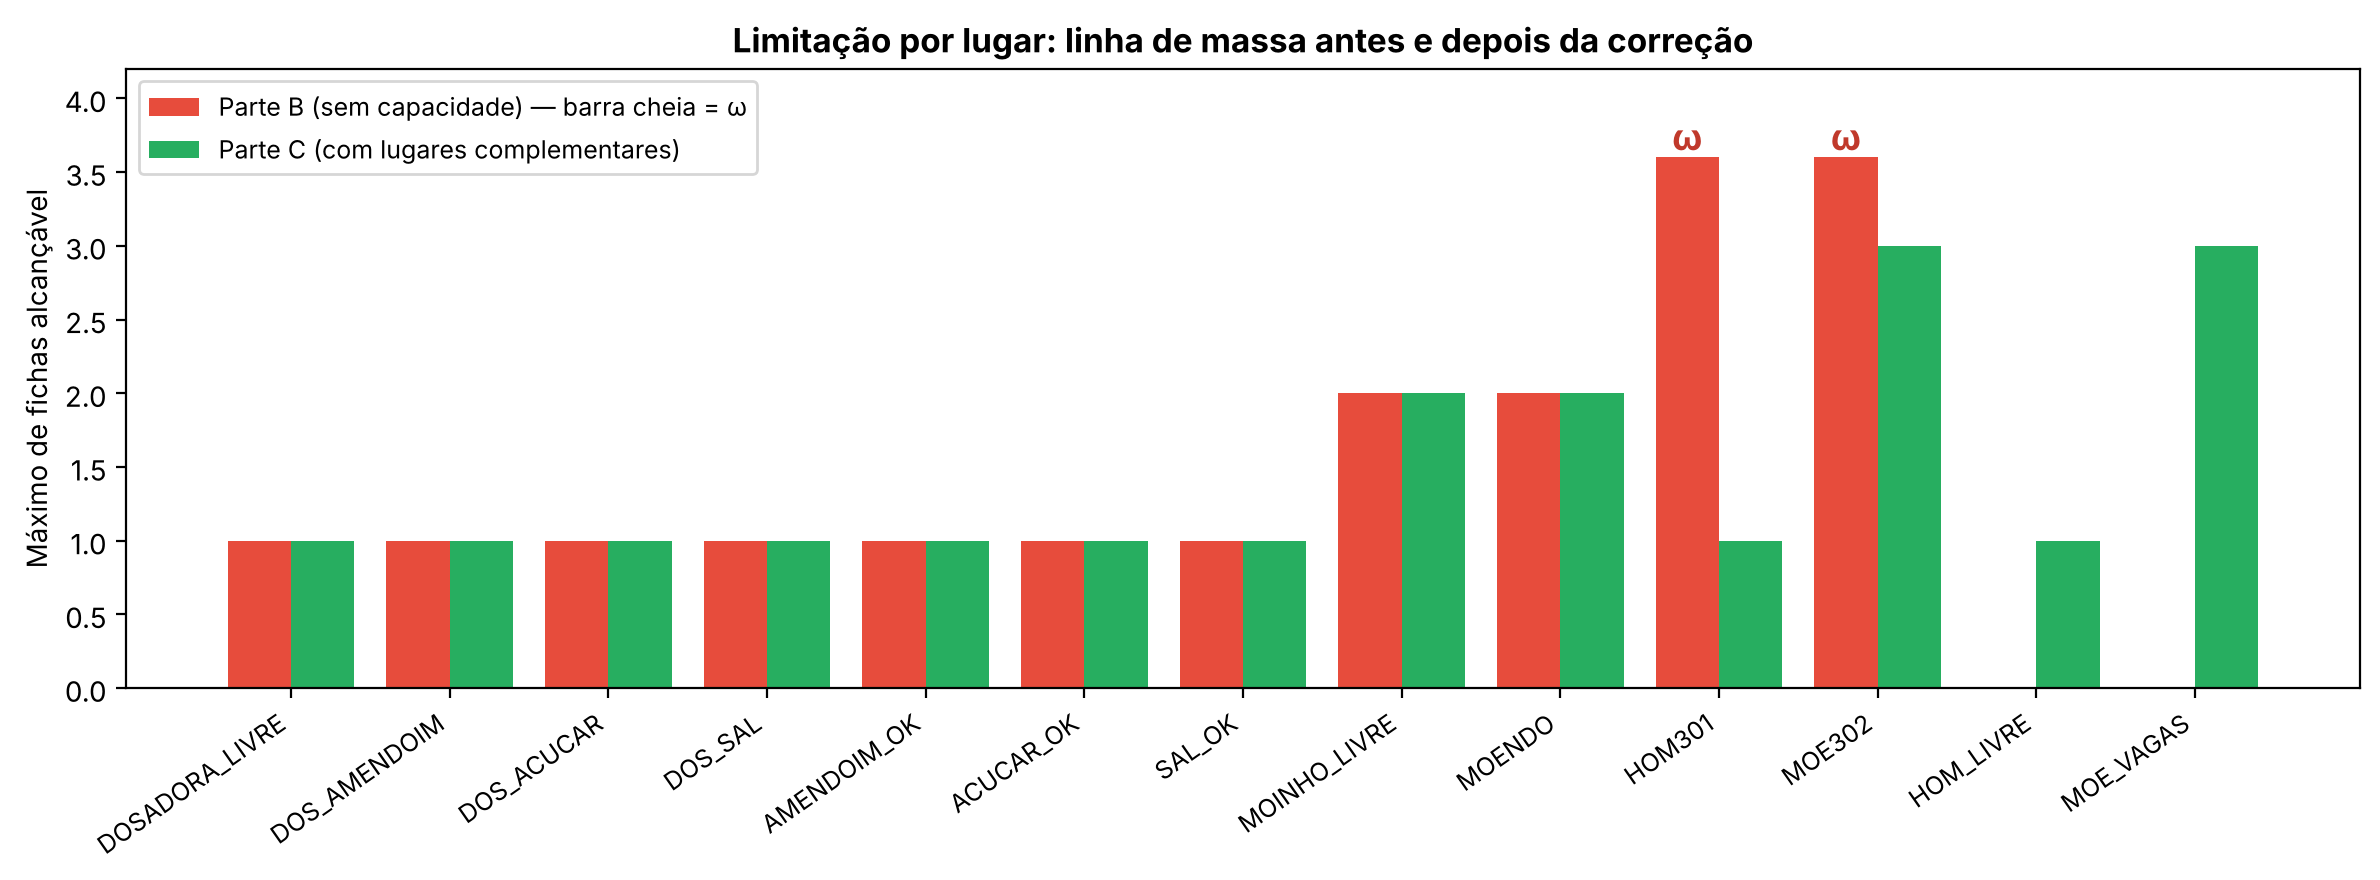

In [14]:
fig, ax = plt.subplots(figsize=(12, 4.5))
nomes = [p.split("_", 1)[1] for p in linha_C.P]
vals_C = [M for M in maximos_C["Máx. de fichas"]]
vals_B = [max(M[i] for M in grafo_B) for i in range(len(linha_B.P))] + [0, 0]
x = range(len(nomes))
ax.bar([k - 0.2 for k in x], [3.6 if v == OMEGA else v for v in vals_B], width=0.4,
       color="#E74C3C", label="Parte B (sem capacidade) — barra cheia = ω")
ax.bar([k + 0.2 for k in x], vals_C, width=0.4, color="#27AE60", label="Parte C (com lugares complementares)")
for k, v in enumerate(vals_B):
    if v == OMEGA:
        ax.text(k - 0.2, 3.65, "ω", ha="center", fontsize=13, fontweight="bold", color="#C0392B")
ax.set_xticks(list(x)); ax.set_xticklabels(nomes, rotation=35, ha="right", fontsize=9)
ax.set_ylabel("Máximo de fichas alcançável"); ax.set_ylim(0, 4.2)
ax.set_title("Limitação por lugar: linha de massa antes e depois da correção", fontweight="bold")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

### Conclusões do notebook

1. **Forno de torra (Parte A):** a árvore de atingibilidade é finita (5 marcações), 1-limitada, viva e reversível. As propriedades S1–S4 foram verificadas exaustivamente, e três leis de conservação (estado único, gás ⇔ torra, exaustor ⇔ forno ligado) foram provadas estruturalmente por $y^T C = 0$. Uma alteração aparentemente inofensiva no reset foi capturada como violação da purga obrigatória.
2. **Linha de massa (Parte B):** a árvore de cobertura mostra $\omega$ no `HOM-301` e na `MOE-302`, uma prova formal de risco de sobrecarga e transbordo quando a prensa é mais lenta que a moagem.
3. **Correção (Parte C):** os lugares complementares tornam a rede limitada com os máximos exatamente iguais às capacidades físicas, sem deadlocks, reversível e viva. Além disso, a lógica permite acionar o moinho reserva `MOI-301B` em paralelo quando necessário — o que a variante conservadora impediria.